# Experiment No.10 : Implementation of Single Layer Artificial Neural Network (ANN)

## Aim
To implement a Single Layer Artificial Neural Network for classifying Iris flowers using their sepal and petal measurements.

## Problem Statement
Develop a neural network model that predicts the species of an Iris flower based on four input features.

## Objectives
- To understand the working of a Single Layer Artificial Neural Network.
- To train and evaluate an ANN model for multiclass classification.

## Theory

An Artificial Neural Network (ANN) is a machine learning model inspired by the structure of the human brain. It consists of interconnected neurons that process input data and produce predictions.

A Single Layer ANN has an input layer and an output layer, without any hidden layer. For multiclass classification, the output layer can use the Softmax activation function to calculate the probability of each class.

In this experiment, the Iris dataset is used to classify flowers into Setosa, Versicolor, and Virginica using four numerical features.

Part 1: Introduction and dataset analysis

In [2]:
# Import libraries for data analysis, visualization, preprocessing and ANN implementation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.utils import to_categorical

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [3]:
# Load the headerless Iris CSV file with appropriate column names

file_path = r"C:\Users\USER\Downloads\iris (1).csv"

columns = [
    "SepalLength",
    "SepalWidth",
    "PetalLength",
    "PetalWidth",
    "Species"
]

df = pd.read_csv(file_path, header=None, names=columns)

print("Iris dataset loaded successfully.")

Iris dataset loaded successfully.


In [4]:
# Display the first five records to understand the dataset structure

display(df.head())

,SepalLength,SepalWidth,PetalLength,PetalWidth,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [5]:
# Check the total number of records and features in the dataset

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 150
Number of columns: 5


In [6]:
# Display column names, data types and non-null counts

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SepalLength  150 non-null    float64
 1   SepalWidth   150 non-null    float64
 2   PetalLength  150 non-null    float64
 3   PetalWidth   150 non-null    float64
 4   Species      150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.9 KB


In [7]:
# Generate descriptive statistics for the numerical features

display(df.describe())

,SepalLength,SepalWidth,PetalLength,PetalWidth
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [8]:
# Count missing values in each column

print("Missing values:")
print(df.isnull().sum())

Missing values:
SepalLength    0
SepalWidth     0
PetalLength    0
PetalWidth     0
Species        0
dtype: int64


In [9]:
# Identify the number of duplicate records in the dataset

print("Duplicate records:", df.duplicated().sum())

Duplicate records: 3


In [10]:
# Count the number of records belonging to each Iris species

species_counts = df["Species"].value_counts()

print("Species distribution:")
print(species_counts)

Species distribution:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


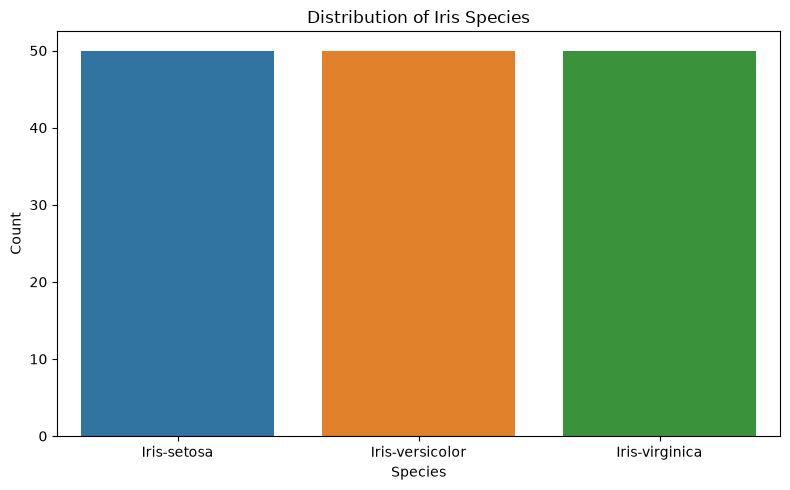

In [11]:
# Plot the distribution of Iris flower species

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Species", hue="Species", legend=False)
plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

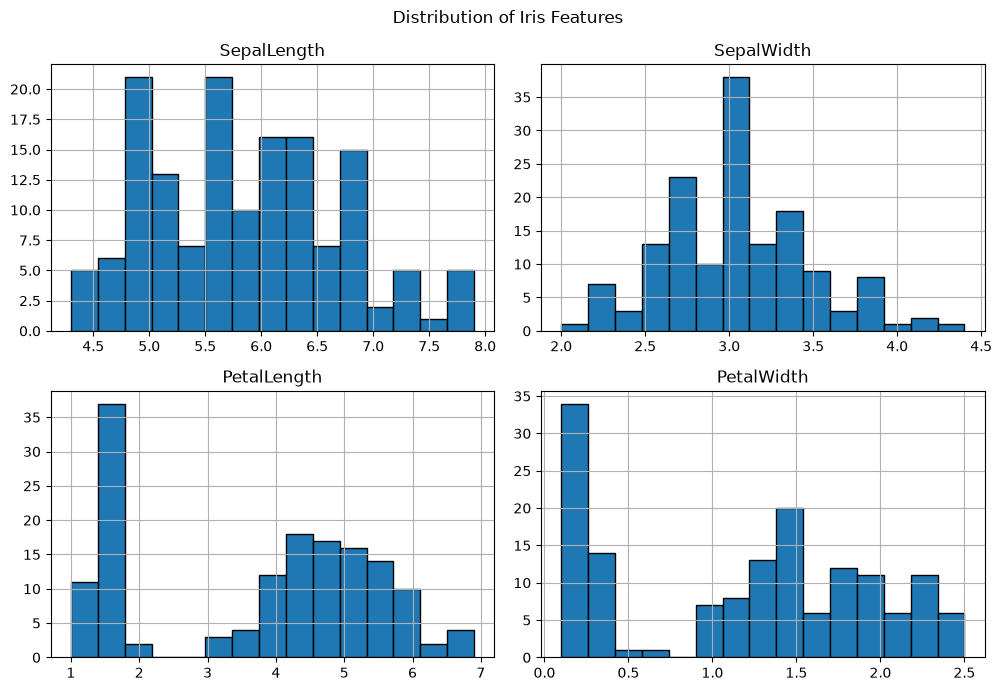

In [12]:
# Visualize the distribution of the four numerical flower features

df[columns[:4]].hist(figsize=(10, 7), bins=15, edgecolor="black")
plt.suptitle("Distribution of Iris Features")
plt.tight_layout()
plt.show()

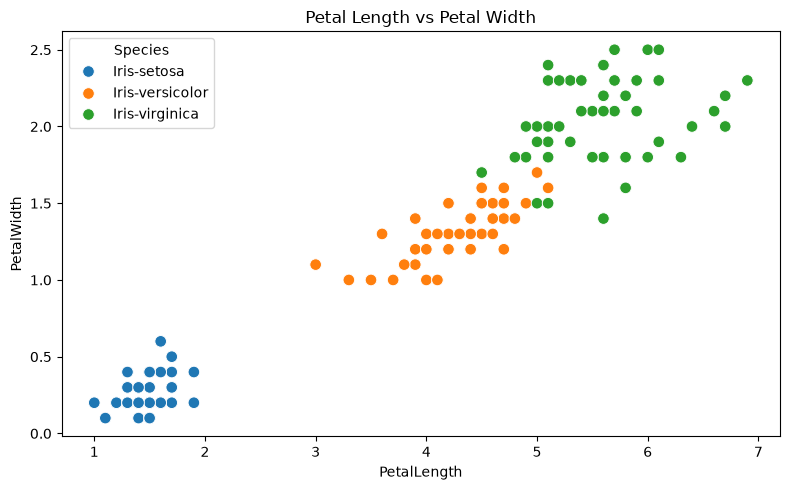

In [13]:
# Compare petal measurements across different Iris species

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="PetalLength",
    y="PetalWidth",
    hue="Species",
    s=70
)
plt.title("Petal Length vs Petal Width")
plt.tight_layout()
plt.show()

Part 2: Preprocessing and ANN implementation

In [15]:
# Separate the four input features from the target species

X = df[columns[:4]]
y = df["Species"]

print("Input features:", X.columns.tolist())
print("Target variable: Species")

Input features: ['SepalLength', 'SepalWidth', 'PetalLength', 'PetalWidth']
Target variable: Species


In [16]:
# Convert species names into numerical labels for neural network training

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Species classes:", label_encoder.classes_)
print("Encoded labels:", np.unique(y_encoded))

Species classes: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']
Encoded labels: [0 1 2]


In [17]:
# Convert numerical class labels into one-hot encoded vectors

y_categorical = to_categorical(y_encoded, num_classes=3)

print("One-hot encoded target shape:", y_categorical.shape)
print("First five encoded targets:")
print(y_categorical[:5])

One-hot encoded target shape: (150, 3)
First five encoded targets:
[[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]]


In [18]:
# Divide the dataset into training and testing sets while preserving class proportions

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_categorical,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 120
Testing samples: 30


In [19]:
# Standardize input features to improve neural network training

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully.")

Feature scaling completed successfully.


In [20]:
# Create a neural network with one output layer and no hidden layer

model = Sequential([
    Input(shape=(4,)),
    Dense(3, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 3)              │            15 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15 (60.00 B)

 Trainable params: 15 (60.00 B)

 Non-trainable params: 0 (0.00 B)

In [22]:
# Train the Single Layer ANN using the training dataset

history = model.fit(
    X_train_scaled,
    y_train,
    epochs=30,
    batch_size=8,
    validation_split=0.2,
    verbose=1
)

print("ANN training completed successfully.")

Epoch 1/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.8021 - loss: 0.4921 - val_accuracy: 0.7917 - val_loss: 0.5408
Epoch 2/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8021 - loss: 0.4896 - val_accuracy: 0.7917 - val_loss: 0.5386
Epoch 3/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8021 - loss: 0.4872 - val_accuracy: 0.7917 - val_loss: 0.5363
Epoch 4/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8125 - loss: 0.4849 - val_accuracy: 0.7917 - val_loss: 0.5342
Epoch 5/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8125 - loss: 0.4825 - val_accuracy: 0.7917 - val_loss: 0.5320
Epoch 6/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8229 - loss: 0.4803 - val_accuracy: 0.7917 - val_loss: 0.5298
Epoch 7/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8229 - loss: 0.4780 - val_accuracy: 0.7917 - val_loss: 0.5277
Epoch 8/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8229 - loss: 0.4758 - val_accuracy: 0.7917 - v

In [23]:
# Evaluate the trained ANN on unseen test data

test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.4801
Test Accuracy: 76.67%


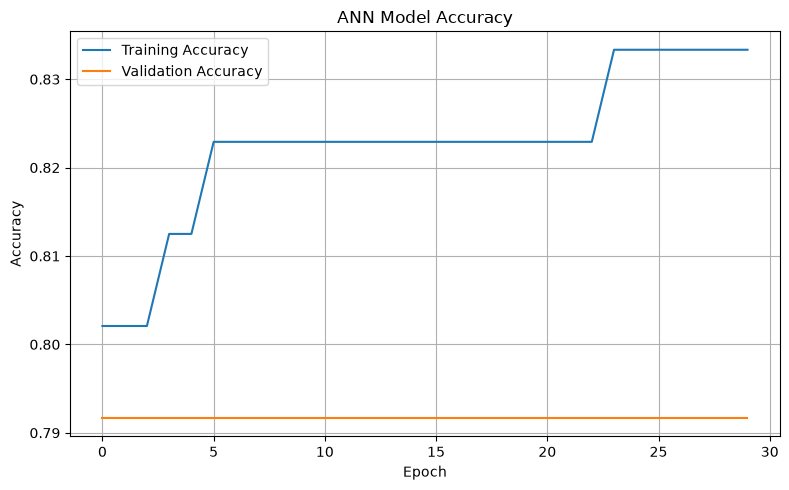

In [24]:
# Visualize the model accuracy over training epochs

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("ANN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

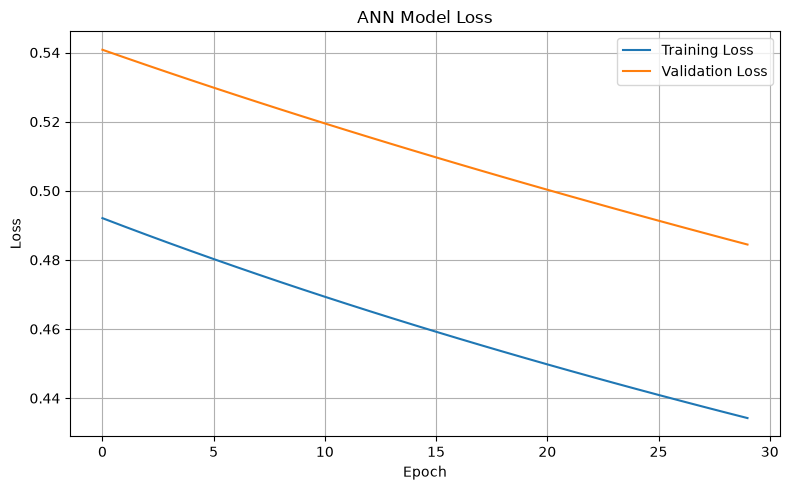

In [25]:
# Visualize the loss reduction during ANN training

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("ANN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [26]:
# Predict Iris species probabilities and convert them into class labels

y_probability = model.predict(X_test_scaled, verbose=0)
y_pred = np.argmax(y_probability, axis=1)
y_actual = np.argmax(y_test, axis=1)

print("Predictions generated successfully.")

Predictions generated successfully.


In [27]:
# Display precision, recall, F1-score and accuracy for each species

print(
    classification_report(
        y_actual,
        y_pred,
        labels=[0, 1, 2],
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.80      0.40      0.53        10
 Iris-virginica       0.60      0.90      0.72        10

       accuracy                           0.77        30
      macro avg       0.80      0.77      0.75        30
   weighted avg       0.80      0.77      0.75        30



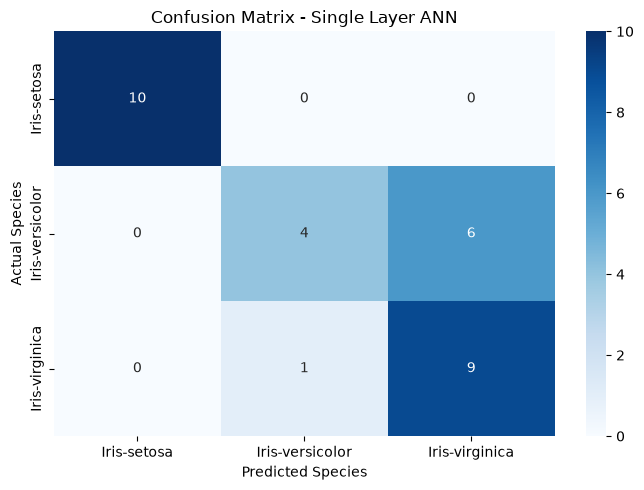

In [28]:
# Evaluate correct and incorrect predictions using a confusion matrix

cm = confusion_matrix(y_actual, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("Confusion Matrix - Single Layer ANN")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()

In [29]:
# Predict the species of a new Iris flower using its four measurements

new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=columns[:4]
)

new_flower_scaled = scaler.transform(new_flower)
prediction = model.predict(new_flower_scaled, verbose=0)
predicted_class = np.argmax(prediction, axis=1)[0]

print("New flower measurements:")
display(new_flower)

print("Predicted species:", label_encoder.inverse_transform([predicted_class])[0])
print("Class probabilities:", np.round(prediction[0], 4))

New flower measurements:


,SepalLength,SepalWidth,PetalLength,PetalWidth
0,5.1,3.5,1.4,0.2


Predicted species: Iris-setosa
Class probabilities: [0.9341 0.0449 0.021 ]


In [30]:
# Summarize the final performance of the Single Layer ANN experiment

print("EXPERIMENT RESULT")
print("-" * 40)
print("Algorithm: Single Layer Artificial Neural Network")
print("Dataset: Iris")
print("Number of input features:", X.shape[1])
print("Number of output classes:", len(label_encoder.classes_))
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print("Training and evaluation completed successfully.")

EXPERIMENT RESULT
----------------------------------------
Algorithm: Single Layer Artificial Neural Network
Dataset: Iris
Number of input features: 4
Number of output classes: 3
Test Accuracy: 76.67%
Training and evaluation completed successfully.


## Conclusion

A Single Layer Artificial Neural Network was implemented successfully for Iris flower classification. The dataset was explored, preprocessed and used to train the model. Its performance was evaluated using accuracy, a classification report and a confusion matrix. The experiment demonstrates how an ANN can perform multiclass classification using numerical features.